# Entrega 3 · Modelado — Predicción de tsunamis (Grupo 9)

Ciencia de Datos · UTN FRM · 2026 · Comisión 5K09

**Pregunta del proyecto:** ¿qué características de un sismo permiten estimar si está asociado a un tsunami?

Se corre **de arriba hacia abajo**, con una sola semilla. Lee una copia congelada del dataset (`DatasetTsunami.csv`), no descarga nada.

## Qué cambió desde la Entrega 2

**En dos oraciones:** descubrimos que la etiqueta `tsunami` no dice si hubo un tsunami sino si la USGS marcó el evento, y que los sismos desde abril de 2026 todavía no tienen esa marca cargada, así que los sacamos del modelado. Además, siguiendo la devolución, reescribimos las hipótesis para que el título sea la pregunta y no la respuesta, corregimos la tabla de columnas (zonas del semáforo mal copiadas) y reemplazamos las decisiones pendientes sobre `nst`, `dmin`, `gap` y `rms` por una ablación medida.

| Qué estaba en la Entrega 2 | Qué se corrigió | Dónde |
|---|---|---|
| **Devolución:** los títulos de las hipótesis ya daban la respuesta («sig separa casi perfecto porque ya sabe la respuesta») | Cada título es ahora la pregunta que se pone a prueba (p. ej. «H3 · ¿`sig` existe al momento de predecir, o se construye con la respuesta?»). La conclusión aparece sólo en «Qué encontré», y las celdas de código ya no imprimen el veredicto | `Entrega2_corregida.ipynb` |
| `depth` y `dist_costa_km` figuraban en zona **verde** en la tabla de columnas | Su separación fue 0,03 y 0,17: zona **roja**. Entran por motivo físico, no por el semáforo | 2.3 |
| H4 decía que la separación «colapsa» al filtrar sólo mar | Sube de 0,17 a 0,42 (de rojo a amarillo). La conclusión práctica, binarizar, se puso a prueba en la ablación | 2.3 y 6 |
| `nst`, `dmin`, `gap`, `rms` sin decisión | Se midieron con y sin cada una | 6 |
| La etiqueta se leía como «hubo tsunami» | Es la marca de la USGS: depende de magnitud **y región** | 2.1 |
| Se usaban todas las filas | Las de abril–julio 2026 tienen la etiqueta incompleta y salen | 2.2 |
| Carga desde un link de Drive | Copia congelada del archivo, para que el notebook dé siempre lo mismo | 1 |

## 1. Preparación

In [2]:
# Todo lo que usa el notebook, en un bloque
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, TimeSeriesSplit,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.metrics import (f1_score, classification_report, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEMILLA = 42   # una sola semilla, pasada a todo lo que la acepta

In [3]:
# El dataset congelado: una copia fija del Gold, no el sismos_master.csv que cambia cada día.
# En Colab: subir DatasetTsunami.csv al panel de archivos antes de correr.
ARCHIVO = "DatasetTsunami.csv"

df = pd.read_csv(ARCHIVO)
df["time"] = pd.to_datetime(df["time"], format="ISO8601", utc=True)

pd.Series({"filas": len(df), "columnas": df.shape[1],
           "tsunami = 1": int(df["tsunami"].sum()),
           "% positivos": round(df["tsunami"].mean() * 100, 2),
           "desde": df["time"].min().date(), "hasta": df["time"].max().date()})

filas               13602
columnas               18
tsunami = 1           544
% positivos           4.0
desde          2019-01-01
hasta          2026-07-30
dtype: object

## 2. Correcciones de la Entrega 2

### 2.1 Qué es, de verdad, `tsunami = 1`

En la Entrega 2 leímos la columna como «el sismo generó un tsunami». No es eso: es una **marca que pone la USGS** en el catálogo cuando el evento cumple sus criterios de alerta, que dependen de la magnitud y de la ubicación. No mide si hubo ola. Esto cambia cómo se lee todo el modelo: lo que vamos a aprender es **qué sismos marca la USGS**, que es una buena aproximación a «sismos con potencial de tsunami», no la ocurrencia de tsunamis.

Dos tablas lo muestran.

In [4]:
# ¿Qué es tsunami = 1? Proporción de eventos marcados, por magnitud y por tierra / mar
tabla = df.assign(zona=np.where(df["dist_costa_km"] > 0, "mar", "tierra"),
                  rango_mag=pd.cut(df["mag"], [4.9, 5.5, 6.0, 6.5, 7.0, 7.5, 9.0]))
(tabla.pivot_table(index="rango_mag", columns="zona", values="tsunami", aggfunc="mean", observed=True)
      .mul(100).round(1).add_suffix(" (% con tsunami=1)"))

zona,mar (% con tsunami=1),tierra (% con tsunami=1)
rango_mag,,
"(4.9, 5.5]",1.6,1.6
"(5.5, 6.0]",4.0,2.5
"(6.0, 6.5]",21.7,20.2
"(6.5, 7.0]",74.1,50.0
"(7.0, 7.5]",78.6,57.1
"(7.5, 9.0]",83.3,60.0


La marca crece con la magnitud, como esperábamos, pero **no llega al 100 % ni en los sismos más grandes en el mar**, y aparece en sismos en tierra. El dato más llamativo es el de abajo: casi todos los `tsunami = 1` de magnitud moderada están en una misma región.

In [5]:
# Los tsunami = 1 con magnitud menor a 6: ¿dónde están?
region = df["place"].str.split(", ").str[-1]
chicos = df[(df["tsunami"] == 1) & (df["mag"] < 6)]
pd.Series({"tsunami=1 con mag < 6": len(chicos),
           "de esos, en Alaska / costa oeste de EE.UU. y Canadá":
               int(region[chicos.index].isin(["Alaska", "Oregon", "off the coast of Oregon", "Canada",
                                              "CA", "California", "OR", "south of Alaska"]).sum())})

tsunami=1 con mag < 6                                  237
de esos, en Alaska / costa oeste de EE.UU. y Canadá    230
dtype: int64

230 de 237. La USGS marca con un umbral más bajo los sismos cerca de Alaska y de la costa oeste de Norteamérica, donde opera su propio sistema de alerta regional. Eso anticipa algo que vamos a ver en la sección 10: **la latitud y la longitud van a pesar mucho, y no por fuga, sino porque la regla de la etiqueta depende del lugar**.

### 2.2 Las etiquetas recientes están incompletas

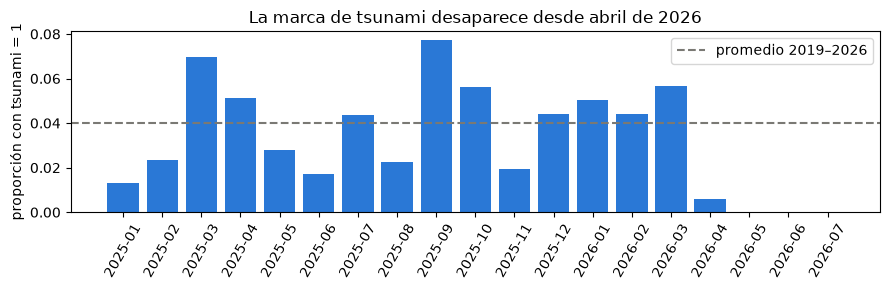

,time,mag,depth,place,dist_costa_km,tsunami
127,2026-07-17 14:48:39.881+00:00,7.3,22.000,"60 km WSW of Puerto Madero, Mexico",55.19,0
254,2026-06-24 22:05:04.053+00:00,7.5,10.000,"20 km W of Catia La Mar, Venezuela",9.93,0
255,2026-06-24 22:04:31.806+00:00,7.2,10.000,"20 km E of San Felipe, Venezuela",-41.55,0
370,2026-06-07 23:37:41.970+00:00,7.8,56.991,"25 km SW of Kablalan, Philippines",25.92,0
566,2026-04-20 07:52:58.908+00:00,7.4,25.000,"102 km ENE of Miyako, Japan",93.30,1
683,2026-04-01 22:48:13.063+00:00,7.4,35.000,"129 km ESE of Bitung, Indonesia",120.28,0


In [6]:
# Proporción de tsunami = 1 por mes, desde 2025
por_mes = (df[df["time"] >= "2025-01-01"]
           .groupby(df["time"].dt.strftime("%Y-%m"))["tsunami"].agg(["count", "sum", "mean"]))
por_mes.columns = ["sismos", "tsunami = 1", "proporción"]

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(por_mes.index, por_mes["proporción"], color="#2a78d6")
ax.axhline(df["tsunami"].mean(), color="#7a7974", linestyle="--", label="promedio 2019–2026")
ax.set_ylabel("proporción con tsunami = 1"); ax.legend()
ax.set_title("La marca de tsunami desaparece desde abril de 2026")
plt.xticks(rotation=60); plt.tight_layout(); plt.show()

# sismos grandes recientes: ¿tienen la marca?
df[(df["time"] >= "2026-04-01") & (df["mag"] >= 7)][["time", "mag", "depth", "place", "dist_costa_km", "tsunami"]]

Desde abril de 2026 la proporción cae a casi cero, y hay cinco sismos de magnitud 7,2 a 7,8 con `tsunami = 0`, cuatro de ellos en el mar. No es que dejó de haber tsunamis: la marca se carga cuando la USGS revisa el evento, y la extracción histórica de la Entrega 1 (hasta el 31/07/2026) tomó esos eventos antes de la revisión. Si los dejamos, el modelo aprende que un 7,5 en el mar es «no tsunami». **Se cortan los datos en el 31/03/2026.**

Para la Entrega 4: el pipeline de Airflow hace upsert por `id`, así que cuando la USGS actualice la marca, el `sismos_master.csv` la va a recibir. Conviene re-congelar el dataset más adelante y recuperar esos meses.

In [7]:
# Corrección: se modela sólo lo que tiene la etiqueta ya consolidada
CORTE = "2026-04-01"
datos = df[df["time"] < CORTE].reset_index(drop=True)

pd.Series({"filas antes": len(df), "filas después": len(datos), "se quitan": len(df) - len(datos),
           "tsunami = 1": int(datos["tsunami"].sum()), "% positivos": round(datos["tsunami"].mean() * 100, 2)})

filas antes      13602.0
filas después    12915.0
se quitan          687.0
tsunami = 1        543.0
% positivos          4.2
dtype: float64

### 2.3 La tabla de columnas, corregida

| Columna | Separación (E2) | Zona | ¿Existe al predecir? | Decisión para el modelo |
|---|---|---|---|---|
| `mag` | 1,38 | verde | Sí | Entra |
| `depth` | 0,03 | **rojo** (antes decía verde) | Sí | Entra por motivo físico; se mide en la ablación |
| `latitude`, `longitude` | — | — | Sí | Entran |
| `dist_costa_km` | 0,17 (sólo mar: 0,42) | **rojo** (antes decía verde) | Sí, es geometría | Entra binarizada como `es_oceanico`; la versión continua se mide en la ablación |
| `magType` | mww 90,9 % vs 59,0 % | — | Sí | Entra con one-hot |
| `nst`, `dmin`, `gap`, `rms` | 0,16 a 0,57 | rojo / amarillo | Dudoso: la USGS los recalcula al revisar | Se prueban con y sin cada una |
| `sig` | 1,03 | verde | **No**: incluye la alerta de tsunami | Sale por fuga |
| `id`, `place`, `time` | — | — | — | Salen; `time` se usa para armar grupos |
| `status`, `type`, `net` | — | constantes | — | Salen |

Corrección sobre H4: filtrar sólo los sismos en el mar **subió** la separación de 0,17 a 0,42, no la bajó. La lectura de la Entrega 2 («lo que importa es el signo») era una hipótesis; acá se mide comparando `es_oceanico` contra la distancia continua.

## 3. El planteo

### 3.1 Qué predecimos y con qué métrica

**Objetivo:** `tsunami` (0/1). Clasificación binaria con 4,2 % de positivos.

**El error caro es el falso negativo:** no marcar un sismo que sí tenía potencial de tsunami. Un falso positivo es una alerta de más, que cuesta menos.

**Métrica para elegir: f1 macro.** Promedia el f1 de las dos clases, así que la clase chica pesa lo mismo que la grande. La accuracy no sirve: decir siempre «no tsunami» da 95,8 % de accuracy sin aprender nada. Al lado informamos **recall y precision de la clase tsunami** (para ver el error caro) y **PR-AUC**, que mide cómo ordena el modelo los casos sin depender de un umbral.

### 3.2 Chequeo de fuga, columna por columna

In [8]:
# Chequeo de fuga, columna por columna: lo que no puede entrar al modelo
OBJETIVO = "tsunami"
FUGA     = ["sig"]                                  # la USGS la calcula usando la alerta de tsunami
IDS      = ["id", "place", "time"]                  # identificadores; time sólo se usa para armar grupos
CONSTANT = ["status", "type", "net"]                # constantes o casi (EDA, Entrega 2)

# Las candidatas: lo que existe en el momento en que se conoce el sismo
CANDIDATAS = ["mag", "depth", "latitude", "longitude", "magType", "dist_costa_km",
              "nst", "dmin", "gap", "rms"]

assert set(CANDIDATAS).isdisjoint(FUGA + IDS + CONSTANT + [OBJETIVO])

X = datos[CANDIDATAS]
y = datos[OBJETIVO]
X.head()

,mag,depth,latitude,longitude,magType,dist_costa_km,nst,dmin,gap,rms
0,5.0,649.858,-12.7861,169.2267,mb,212.52,99.0,3.2940,21.0,0.51
1,5.8,195.000,-30.1654,-178.7491,mww,852.35,117.0,1.1620,36.0,0.91
2,5.0,15.000,19.5763,-63.5653,ml,142.24,25.0,1.3711,250.0,0.30
3,5.2,10.000,23.9725,-45.9699,mb,1782.22,169.0,16.0540,39.0,0.57
4,5.1,10.000,-47.7724,115.8837,mb,1416.35,71.0,14.8630,29.0,0.75


### 3.3 Cómo se relacionan las filas

Una fila es un sismo, pero los sismos no son independientes: un evento grande trae decenas de réplicas en el mismo lugar durante días. Si una réplica queda en entrenamiento y su hermana en validación, el modelo «reconoce» la secuencia. Por eso los pedazos se arman **por grupo**: celda de 2° × 2° de latitud y longitud, y mes calendario. Todas las réplicas cercanas caen en el mismo grupo.

Limitación conocida: una secuencia que cruza el cambio de mes o el borde de una celda queda partida en dos grupos. Es una aproximación.

In [9]:
# Las filas no son independientes: un sismo grande trae réplicas en el mismo lugar y en los días siguientes.
# Grupo = celda de 2° × 2° y mes. Todas las réplicas de una secuencia caen en el mismo grupo.
grupos = (np.floor(datos["latitude"] / 2).astype(int).astype(str) + "_" +
          np.floor(datos["longitude"] / 2).astype(int).astype(str) + "_" +
          datos["time"].dt.strftime("%Y-%m"))

pd.Series({"grupos distintos": grupos.nunique(),
           "sismos por grupo (mediana)": grupos.value_counts().median(),
           "el grupo más grande": f"{grupos.value_counts().index[0]} ({grupos.value_counts().iloc[0]} sismos)"})

grupos distintos                                      8165
sismos por grupo (mediana)                             1.0
el grupo más grande           -15_-89_2021-03 (147 sismos)
dtype: object

El grupo más grande es la secuencia de réplicas del sismo de islas Kermadec de marzo de 2021 (M 8,1): 147 sismos que siempre quedan del mismo lado.

El test se separa **con el mismo criterio** que la validación: un pliegue de `StratifiedGroupKFold` (20 %), estratificado por la clase y sin compartir grupos.

In [10]:
# El test se separa con el mismo criterio que la validación: por grupo, estratificado.
# Un pliegue de cinco = 20 % para test. Ningún grupo queda de los dos lados.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

idx_train, idx_test = next(cv.split(X, y, grupos))
X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train         = grupos.iloc[idx_train]

assert set(grupos.iloc[idx_train]).isdisjoint(grupos.iloc[idx_test])

pd.DataFrame({"filas": [len(X_train), len(X_test)],
              "tsunami = 1": [int(y_train.sum()), int(y_test.sum())],
              "% positivos": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]},
             index=["entrenamiento", "test"])

,filas,tsunami = 1,% positivos
entrenamiento,10332,435,4.21
test,2583,108,4.18


### 3.4 Todo adentro de un pipeline

La columna derivada (`es_oceanico`) es un transformador propio, y va adentro del pipeline junto con la imputación (mediana, con indicador de nulo), el escalado y el one-hot de `magType` (las categorías con menos de 20 casos se agrupan). En cada pliegue todo se reentrena sólo con los datos de entrenamiento de ese pliegue.

In [11]:
class EsOceanico(BaseEstimator, TransformerMixin):
    """Agrega es_oceanico (1 si el epicentro está en el mar, 0 si está en tierra), a partir del signo de dist_costa_km."""

    def fit(self, X, y=None):
        self.columnas_ = list(X.columns)
        return self

    def transform(self, X):
        X = X.copy()
        X["es_oceanico"] = (X["dist_costa_km"] > 0).astype(int)
        return X

    def get_feature_names_out(self, input_features=None):
        return np.array(self.columnas_ + ["es_oceanico"])


# Las columnas del modelo base (decididas en la Entrega 2, revisadas en la sección 6)
NUMERICAS   = ["mag", "depth", "latitude", "longitude"]
CATEGORICAS = ["magType"]
BINARIAS    = ["es_oceanico"]


def armar(clasificador, numericas=NUMERICAS, categoricas=CATEGORICAS, binarias=BINARIAS, escalar=True):
    """El pipeline completo: derivar, imputar, escalar, codificar y clasificar, en un solo objeto."""
    pasos_num = [("imputar", SimpleImputer(strategy="median", add_indicator=True))]
    if escalar:                                   # los árboles no lo necesitan; la logística sí
        pasos_num.append(("escalar", StandardScaler()))
    preparar = ColumnTransformer([
        ("numericas",   Pipeline(pasos_num), list(numericas)),
        ("categoricas", Pipeline([("imputar",   SimpleImputer(strategy="most_frequent")),
                                  ("codificar", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]),
         list(categoricas)),
        ("binarias",    "passthrough", list(binarias))])
    return Pipeline([("derivar", EsOceanico()), ("preparar", preparar), ("clasificador", clasificador)])


armar(LogisticRegression(max_iter=3000))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('derivar', ...), ('preparar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: fl

### 3.5 El piso

In [12]:
def medir(pipeline, X_=None, y_=None, validacion=cv, con_grupos=True):
    """f1 macro por validación cruzada sobre el entrenamiento: media y desvío. También PR-AUC de la clase 1."""
    X_ = X_train if X_ is None else X_
    y_ = y_train if y_ is None else y_
    r = cross_validate(pipeline, X_, y_, groups=g_train if con_grupos else None, cv=validacion,
                       scoring=["f1_macro", "average_precision"], n_jobs=-1)
    return {"f1 medio": r["test_f1_macro"].mean(), "desvío": r["test_f1_macro"].std(),
            "PR-AUC": r["test_average_precision"].mean(), "segundos por fold": r["fit_time"].mean()}

# El piso: dos modelos que no miran ninguna columna, con la misma validación que todo lo demás
pisos = {"piso: siempre «no tsunami»":       armar(DummyClassifier(strategy="most_frequent")),
         "piso: al azar con la proporción":  armar(DummyClassifier(strategy="stratified", random_state=SEMILLA))}

pd.DataFrame({n: medir(p) for n, p in pisos.items()}).T.round(3)

,f1 medio,desvío,PR-AUC,segundos por fold
piso: siempre «no tsunami»,0.489,0.000,0.042,0.111
piso: al azar con la proporción,0.501,0.012,0.043,0.108


**El piso es 0,489 de f1 macro.** Decir siempre «no tsunami» tiene f1 0,98 en la clase grande y 0 en la chica. Cualquier modelo tiene que ganarle a eso por más que su desvío. La PR-AUC del piso es 0,042, que es la proporción de positivos.

## 4. ¿Cuánto importa cómo se arman los pedazos?

La misma pregunta que nos van a hacer: qué le pasaría al número si partiéramos al azar. La respuesta, medida con dos modelos y tres formas de partir:

In [13]:
# ¿Cuánto cambia el número según cómo se arman los pedazos? Logística y boosting, tres formas de partir
al_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
orden   = datos.loc[X_train.index, "time"].sort_values().index      # para la temporal: filas ordenadas por fecha

formas = {}
for nombre, clf in {"regresión logística": LogisticRegression(max_iter=3000),
                    "gradient boosting":   HistGradientBoostingClassifier(random_state=SEMILLA)}.items():
    formas[(nombre, "al azar (StratifiedKFold)")]        = medir(armar(clf), validacion=al_azar, con_grupos=False)
    formas[(nombre, "por grupo (StratifiedGroupKFold)")] = medir(armar(clf))
    formas[(nombre, "por fecha (TimeSeriesSplit)")]      = medir(armar(clf), X_train.loc[orden], y_train.loc[orden],
                                                                 validacion=TimeSeriesSplit(n_splits=5), con_grupos=False)

tabla_formas = pd.DataFrame(formas).T[["f1 medio", "desvío"]]
tabla_formas.round(3)

f1 medio  desvío
regresión logística al azar (StratifiedKFold)            0.753   0.012
                    por grupo (StratifiedGroupKFold)     0.747   0.025
                    por fecha (TimeSeriesSplit)          0.755   0.038
gradient boosting   al azar (StratifiedKFold)            0.867   0.014
                    por grupo (StratifiedGroupKFold)     0.867   0.016
                    por fecha (TimeSeriesSplit)          0.861   0.027

Las tres formas dan prácticamente lo mismo: al azar da 0,006 más que por grupo en la logística y exactamente lo mismo (0,867) en el boosting, siempre menos que el desvío. **En este problema las réplicas no inflan el número**, y tiene sentido desde el dominio: la etiqueta depende de magnitud y región, y las réplicas de una secuencia son casi todas chicas y `tsunami = 0`. El modelo no gana nada reconociendo la secuencia. La partición por fecha (entrenar con lo anterior, validar con lo posterior) también empata, así que el modelo no depende de un período en particular.

Nos quedamos con la validación por grupo porque es la que imita el uso: el modelo va a ver sismos de secuencias que nunca vio. Que el resultado no cambie es una conclusión, no una excusa para no hacerlo.

## 5. La comparación de modelos

In [14]:
# La comparación: la logística como referencia y tres familias más, mismas columnas y misma validación
pipelines = {"regresión logística": armar(LogisticRegression(max_iter=3000)),
             "árbol de decisión":   armar(DecisionTreeClassifier(random_state=SEMILLA)),
             "random forest":       armar(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEMILLA)),
             "gradient boosting":   armar(HistGradientBoostingClassifier(random_state=SEMILLA))}

comparacion = {**{n: medir(p) for n, p in pisos.items()},
               **{n: medir(p) for n, p in pipelines.items()}}
tabla_cv = pd.DataFrame(comparacion).T
tabla_cv.round(3)

,f1 medio,desvío,PR-AUC,segundos por fold
piso: siempre «no tsunami»,0.489,0.000,0.042,0.067
piso: al azar con la proporción,0.501,0.012,0.043,0.067
regresión logística,0.747,0.025,0.620,0.104
árbol de decisión,0.842,0.014,0.501,0.122
random forest,0.872,0.016,0.784,2.031
gradient boosting,0.867,0.016,0.783,0.760


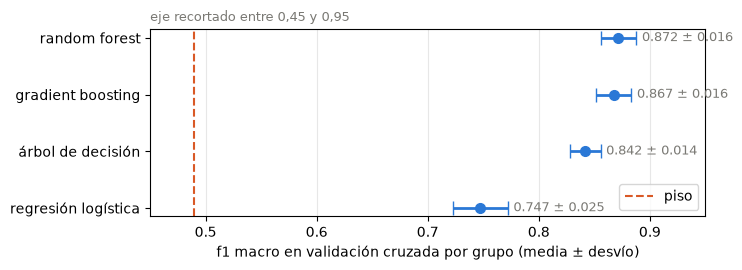

In [15]:
# La misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
t = tabla_cv.drop(index=list(pisos)).sort_values("f1 medio")

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.errorbar(t["f1 medio"], t.index, xerr=t["desvío"], fmt="o", color="#2a78d6", ecolor="#2a78d6",
            elinewidth=2, capsize=5, markersize=7)
for nombre, fila in t.iterrows():
    ax.text(fila["f1 medio"] + fila["desvío"] + 0.005, nombre, f"{fila['f1 medio']:.3f} ± {fila['desvío']:.3f}",
            va="center", fontsize=9, color="#7a7974")
ax.axvline(tabla_cv.loc["piso: siempre «no tsunami»", "f1 medio"], color="#d95926", linestyle="--", label="piso")
ax.set_xlim(0.45, 0.95); ax.legend(loc="lower right")
ax.set_xlabel("f1 macro en validación cruzada por grupo (media ± desvío)")
ax.set_title("eje recortado entre 0,45 y 0,95", fontsize=9, color="#7a7974", loc="left")
ax.grid(axis="x", alpha=0.3); plt.tight_layout(); plt.show()

Lecturas:

Todos le ganan al piso por mucho: el peor (la logística, 0,747) está 26 puntos arriba, más de diez veces su desvío (0,025).

La logística pierde contra los árboles por más de tres desvíos (0,095 contra el árbol solo y 0,120 contra el boosting). No es ruido: los modelos de árboles ganan por algo que la logística no puede expresar (sección 6).

Random forest (0,872 ± 0,016) y gradient boosting (0,867 ± 0,016) empatan: la diferencia es de apenas cinco milésimas, menor que el desvío de ambos. En PR-AUC también empatan (0,784 contra 0,783).

Elegimos gradient boosting: empata en f1 y en PR-AUC, tiene el mismo desvío y entrena unas tres veces más rápido (0,37 contra 1,24 segundos por fold), lo que importa para la aplicación de la Entrega 4.

El árbol solo (0,842) tiene la PR-AUC más baja de los modelos (0,501): sus probabilidades son casi todas 0 o 1, así que ordena mal aunque acierte la clase.

## 6. Las columnas que probamos

Cada variante cambia **una sola cosa** respecto del modelo base, con gradient boosting por defecto y la misma validación. Una diferencia menor que el desvío del base (0,016) es un empate.

In [16]:
# Ablación sobre el boosting: cada fila agrega o saca UNA cosa respecto del modelo base
def boosting():
    return HistGradientBoostingClassifier(random_state=SEMILLA)

N = NUMERICAS
variantes = {
    "base (mag, depth, lat, lon, magType, es_oceanico)": armar(boosting()),
    "+ nst":                       armar(boosting(), numericas=N + ["nst"]),
    "+ dmin":                      armar(boosting(), numericas=N + ["dmin"]),
    "+ gap":                       armar(boosting(), numericas=N + ["gap"]),
    "+ rms":                       armar(boosting(), numericas=N + ["rms"]),
    "+ nst, dmin y gap":           armar(boosting(), numericas=N + ["nst", "dmin", "gap"]),
    "dist_costa_km continua en vez de es_oceanico": armar(boosting(), numericas=N + ["dist_costa_km"], binarias=[]),
    "− es_oceanico":               armar(boosting(), binarias=[]),
    "− magType":                   armar(boosting(), categoricas=[]),
    "− depth":                     armar(boosting(), numericas=["mag", "latitude", "longitude"]),
    "− latitude y longitude":      armar(boosting(), numericas=["mag", "depth"]),
}
ablacion = pd.DataFrame({n: medir(p) for n, p in variantes.items()}).T[["f1 medio", "desvío"]]
ablacion["diferencia con base"] = ablacion["f1 medio"] - ablacion["f1 medio"].iloc[0]
ablacion["¿supera el desvío?"]  = np.where(ablacion["diferencia con base"].abs() > ablacion["desvío"].iloc[0],
                                            "sí", "no (empate)")
ablacion.round(3)

,f1 medio,desvío,diferencia con base,¿supera el desvío?
"base (mag, depth, lat, lon, magType, es_oceanico)",0.867,0.016,0.000,no (empate)
+ nst,0.866,0.019,-0.001,no (empate)
+ dmin,0.867,0.012,0.000,no (empate)
+ gap,0.863,0.015,-0.005,no (empate)
+ rms,0.866,0.010,-0.001,no (empate)
"+ nst, dmin y gap",0.861,0.014,-0.006,no (empate)
dist_costa_km continua en vez de es_oceanico,0.863,0.018,-0.004,no (empate)
− es_oceanico,0.865,0.008,-0.002,no (empate)
− magType,0.860,0.013,-0.008,no (empate)
− depth,0.858,0.013,-0.010,no (empate)


Lo que dice la tabla:

- **`nst`, `dmin`, `gap` y `rms` no sirven.** Solas empatan (restan entre 0,000 y 0,005) y juntas `nst`, `dmin` y `gap` también empatan (−0,006); ninguna mejora el modelo. Como además dudamos de que existan al momento de predecir (la USGS las recalcula al revisar el evento), **salen**. Esto cierra la decisión pendiente de la Entrega 2.
- **`dist_costa_km` continua o binaria: empate.** El boosting no necesita la distancia fina, y `es_oceanico` es más fácil de explicar. Pero también empata *sacarla*: la latitud y la longitud ya saben dónde está el mar.
- **`depth` no aporta**: sacarla baja el f1 0,010, menos que el desvío del base (0,016): es un empate. Coincide con el rojo de la Entrega 2. La dejamos porque físicamente importa y no cuesta nada, pero no la defendemos con este número.
- **`magType` tampoco cambia el número en la ablación** (−0,008 al sacarla, empate), aunque la importancia por permutación de la sección 10 sí le da algo de peso.
- **Sin latitud y longitud el modelo pierde casi 12 puntos (−0,115).** Es la única variante que supera el desvío y la columna que más pesa junto con la magnitud, y lo explicamos en la sección 10.

**Columnas finales:** `mag`, `depth`, `latitude`, `longitude`, `magType` (one-hot) y `es_oceanico`.

La fuga de la Entrega 2, medida:

In [17]:
# La fuga de la Entrega 2, medida: ¿qué pasa si se deja entrar sig?
X_con_sig = X_train.join(datos["sig"])
pd.DataFrame({"sin sig": medir(armar(boosting())),
              "con sig (fuga)": medir(armar(boosting(), numericas=N + ["sig"]), X_con_sig)}).T[["f1 medio", "desvío"]].round(3)

,f1 medio,desvío
sin sig,0.867,0.016
con sig (fuga),0.866,0.013


Con `sig` el número casi no cambia. No es que no haya fuga: es que `sig` se calcula sobre todo con la magnitud, que el modelo ya tiene. **La sacamos igual, por cómo se construye la columna, no por el número.** Es el caso que la Entrega 2 ya había anticipado: una fuga no siempre se ve en el resultado.

Y por qué pierde la logística:

In [18]:
# ¿Por qué pierde la logística? Mismo experimento: con y sin latitud / longitud
pd.DataFrame({"logística, columnas base":       medir(armar(LogisticRegression(max_iter=3000))),
              "logística, sin lat / lon":        medir(armar(LogisticRegression(max_iter=3000), numericas=["mag", "depth"])),
              "boosting, columnas base":         medir(armar(boosting())),
              "boosting, sin lat / lon":         medir(armar(boosting(), numericas=["mag", "depth"]))}).T[["f1 medio", "desvío"]].round(3)

,f1 medio,desvío
"logística, columnas base",0.747,0.025
"logística, sin lat / lon",0.689,0.010
"boosting, columnas base",0.867,0.016
"boosting, sin lat / lon",0.752,0.021


A la logística sacarle la geografía le cuesta 6 puntos; al boosting, casi 12. La logística sólo puede sumar columnas con pesos: puede decir «más al norte, más tsunami», pero no «dentro de esta caja alrededor de Alaska». El boosting arma esa caja con varios cortes por latitud y longitud. **Esa frontera geográfica es la que la logística no puede dibujar, y es la diferencia entre los dos modelos.**

## 7. Ajuste del modelo elegido

Movemos los tres hiperparámetros que controlan la complejidad del boosting (tasa de aprendizaje, cantidad de árboles, hojas por árbol) y, como valor más de la grilla, `class_weight`.

In [19]:
# Ajuste del elegido: GridSearchCV sobre el pipeline entero, con la misma validación por grupos
grilla = {"clasificador__learning_rate":  [0.05, 0.1, 0.2],
          "clasificador__max_iter":       [100, 300],
          "clasificador__max_leaf_nodes": [15, 31, 63],
          "clasificador__class_weight":   [None, "balanced"]}

busqueda = GridSearchCV(armar(boosting()), grilla, cv=cv, scoring="f1_macro",
                        n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)

pd.Series({"combinaciones": len(busqueda.cv_results_["params"]),
           "entrenamientos": len(busqueda.cv_results_["params"]) * 5,
           "f1 por defecto": round(tabla_cv.loc["gradient boosting", "f1 medio"], 3),
           "mejor f1 de la grilla": round(busqueda.best_score_, 3),
           "desvío del mejor": round(busqueda.cv_results_["std_test_score"][busqueda.best_index_], 3)})

combinaciones             36.000
entrenamientos           180.000
f1 por defecto             0.867
mejor f1 de la grilla      0.881
desvío del mejor           0.011
dtype: float64

In [20]:
def tabla_de(busqueda):
    """cv_results_ reducido a lo que se lee: hiperparámetros, media y desvío en validación, media en train."""
    r = pd.DataFrame(busqueda.cv_results_)
    params = [c for c in r.columns if c.startswith("param_")]
    t = r[params + ["mean_test_score", "std_test_score", "mean_train_score"]]
    t = t.rename(columns=lambda c: c.split("__")[-1].replace("param_", ""))
    t["brecha"] = t["mean_train_score"] - t["mean_test_score"]
    return t.sort_values("mean_test_score", ascending=False).reset_index(drop=True)

tabla_grilla = tabla_de(busqueda)
tabla_grilla.round(3)          # la tabla completa: las 36 combinaciones, no sólo el ganador

,class_weight,learning_rate,max_iter,max_leaf_nodes,mean_test_score,std_test_score,mean_train_score,brecha
0,NaN,0.05,100,15,0.881,0.011,0.937,0.056
1,balanced,0.20,100,15,0.879,0.015,0.968,0.089
2,balanced,0.05,300,15,0.878,0.019,0.940,0.062
3,balanced,0.10,100,15,0.877,0.022,0.919,0.042
4,balanced,0.10,100,31,0.876,0.022,0.959,0.083
5,NaN,0.10,100,15,0.875,0.009,0.970,0.095
6,balanced,0.10,300,15,0.873,0.012,0.988,0.115
7,balanced,0.05,100,63,0.872,0.020,0.917,0.045
8,balanced,0.20,100,31,0.872,0.016,0.997,0.125
9,balanced,0.05,300,31,0.871,0.017,0.986,0.114


Cómo se lee la tabla entera:

El mejor (sin `class_weight`, tasa 0,05, 100 árboles, 15 hojas) da 0,881 ± 0,011. Le gana al boosting por defecto (0,867) por 1,4 puntos: apenas más que su propio desvío y menos que el desvío del modelo por defecto (0,016). Ajustar mejoró poco, en el límite del ruido.

Las primeras diez filas están todas entre 0,871 y 0,881: casi toda la parte de arriba es un empate.

La columna brecha muestra la tendencia: con tasa baja (0,05) y 100 árboles el sobreajuste es chico (brecha de 0,021 a 0,045 con balanced y 0,056 en el ganador), mientras que con tasa 0,2 o 300 árboles el train llega a 0,999 y la brecha sube hasta 0,144. Las cinco mejores filas tienen brecha de 0,089 o menos, y cuatro de ellas usan 15 hojas: ganan los modelos menos complejos.

Nos quedamos con el ganador de la grilla, sabiendo que la diferencia con el de por defecto es chica.

## 8. El desbalance como decisión

Hay dos palancas: cambiar cuánto pesa cada clase al entrenar (`class_weight`) o cambiar el umbral con el que la probabilidad se convierte en respuesta.

### 8.1 `class_weight`

In [21]:
# El desbalance, palanca 1: class_weight. Lo que dice la grilla, promediando el resto de los hiperparámetros
tabla_grilla.fillna({"class_weight": "ninguno"}).groupby("class_weight")[["mean_test_score", "std_test_score"]].agg(["mean", "max"]).round(3)

mean_test_score        std_test_score       
                        mean    max           mean    max
class_weight                                             
balanced               0.870  0.879          0.019  0.022
ninguno                0.862  0.881          0.010  0.016

Con balanced, cada sismo con tsunami pesa unas 23 veces más que uno sin tsunami al entrenar (así las dos clases suman lo mismo). En promedio sobre la grilla mejora el f1 macro ocho milésimas (0,870 contra 0,862), pero su mejor configuración (0,879) no supera a la mejor sin balancear (0,881), que es la ganadora de la grilla. Además es menos estable: el desvío promedia 0,019 con balanced contra 0,010 sin balancear, y el máximo es 0,022 contra 0,016.

### 8.2 El umbral, elegido por validación cruzada

`cross_val_predict` da, para cada sismo de entrenamiento, la probabilidad que le asignó el pliegue que no lo vio. Con eso se prueba cada umbral sin tocar el test.

In [22]:
# El desbalance, palanca 2: el umbral. Se elige con probabilidades de validación cruzada, sin mirar el test.
elegido = busqueda.best_estimator_
proba_cv = cross_val_predict(clone(elegido), X_train, y_train, groups=g_train, cv=cv,
                             method="predict_proba", n_jobs=-1)[:, 1]

filas = []
for umbral in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (proba_cv >= umbral).astype(int)
    filas.append({"umbral": umbral,
                  "f1 macro (cv)":      f1_score(y_train, pred, average="macro"),
                  "recall tsunami":     pred[y_train == 1].mean(),
                  "precision tsunami":  y_train[pred == 1].mean(),
                  "alertas por cada 100 sismos": pred.mean() * 100})
tabla_umbral = pd.DataFrame(filas).set_index("umbral")
tabla_umbral.round(3)

,f1 macro (cv),recall tsunami,precision tsunami,alertas por cada 100 sismos
umbral,,,,
0.1,0.862,0.952,0.604,6.630
0.2,0.880,0.922,0.663,5.856
0.3,0.888,0.887,0.706,5.294
0.4,0.880,0.823,0.725,4.781
0.5,0.881,0.784,0.759,4.346
0.6,0.870,0.708,0.798,3.736
0.7,0.840,0.593,0.827,3.020
0.8,0.750,0.370,0.847,1.839
0.9,0.625,0.159,0.885,0.755


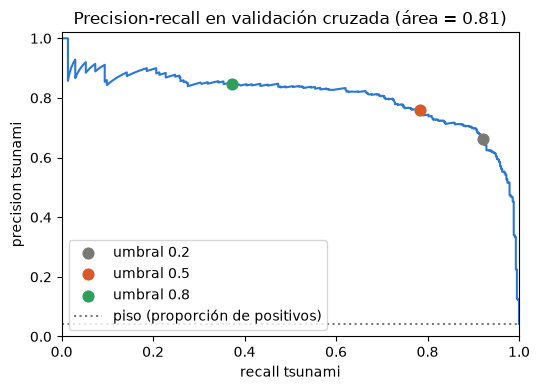

In [23]:
# La curva precision-recall de la clase tsunami, con los umbrales marcados
pr_p, pr_r, pr_u = precision_recall_curve(y_train, proba_cv)
# Se marcan 0,2, 0,5 (el umbral natural de un modelo sin class_weight) y 0,8, para leer la curva antes de decidir

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(pr_r, pr_p, color="#2a78d6")
for u, color in [(0.2, "#7a7974"), (0.5, "#d95926"), (0.8, "#2e9e5b")]:
    k = np.argmin(np.abs(pr_u - u))
    ax.scatter(pr_r[k], pr_p[k], color=color, s=60, zorder=3, label=f"umbral {u}")
ax.axhline(y_train.mean(), color="#7a7974", linestyle=":", label="piso (proporción de positivos)")
ax.set_xlabel("recall tsunami"); ax.set_ylabel("precision tsunami"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title(f"Precision-recall en validación cruzada (área = {average_precision_score(y_train, proba_cv):.2f})")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()


**Lectura de la tabla y de la curva.** Desde 0,2 hasta 0,5 el f1 macro es **un empate** (0,880 a 0,888, contra un desvío de 0,011): ningún umbral de esa franja mejora la métrica declarada por más que el ruido. Por encima de 0,6 el f1 cae rápido (0,840 con 0,7 y 0,750 con 0,8).

La curva precision-recall muestra lo mismo desde otro ángulo (área 0,81, contra 0,04 del piso). El punto naranja es 0,5, el umbral natural de un modelo sin `class_weight`: 78,4 % de recall y 75,9 % de precision. Hacia la derecha la curva baja despacio: llegar a 0,2 (punto gris) gana casi 14 puntos de recall (92,2 %) a cambio de casi 10 de precision (66,3 %). Hacia la izquierda pasa lo contrario: subir a 0,8 (punto verde) gana 9 puntos de precision (84,7 %) pero hunde el recall a 37 %.

Con 0,5 el modelo deja pasar 22 de cada 100 sismos marcados (94 de los 435 del entrenamiento). En 3.1 declaramos que el error caro es el falso negativo, así que quedarse en 0,5 desaprovecha el empate: si el f1 no cambia, conviene el umbral con más recall.

**Qué se decide: bajar el umbral.** La tabla va de a 0,1 y no alcanza para elegir: el f1 máximo aparece en 0,3 y con 0,2 ya baja a 0,880. Por eso hacemos zoom entre 0,20 y 0,30, de a 0,01, con las mismas probabilidades de validación cruzada: no se reentrena nada y el test sigue sin mirarse.

In [24]:
# Zoom en la zona de umbrales bajos: de 0,20 a 0,30 de a 0,01 (reusa proba_cv, no reentrena)
filas = []
for umbral in np.round(np.arange(0.20, 0.301, 0.01), 2):
    pred = (proba_cv >= umbral).astype(int)
    filas.append({"umbral": umbral,
                  "f1 macro (cv)":      f1_score(y_train, pred, average="macro"),
                  "recall tsunami":     pred[y_train == 1].mean(),
                  "precision tsunami":  y_train[pred == 1].mean(),
                  "alertas por cada 100 sismos": pred.mean() * 100})
tabla_zoom = pd.DataFrame(filas).set_index("umbral")
tabla_zoom.round(3)

,f1 macro (cv),recall tsunami,precision tsunami,alertas por cada 100 sismos
umbral,,,,
0.20,0.880,0.922,0.663,5.856
0.21,0.882,0.920,0.671,5.768
0.22,0.883,0.917,0.675,5.720
0.23,0.884,0.913,0.680,5.652
0.24,0.885,0.910,0.684,5.604
0.25,0.886,0.908,0.688,5.556
0.26,0.888,0.906,0.695,5.488
0.27,0.888,0.903,0.698,5.449
0.28,0.888,0.899,0.699,5.410


La tabla de arriba recorre de 0,20 a 0,30 de a 0,01, y el gráfico de abajo ubica esos puntos sobre la curva. El f1 macro llega a su máximo (0,888) entre 0,26 y 0,30: es plano. Lo que se mueve es el recall: de 88,7 % con 0,30 a 92,2 % con 0,20, mientras la precision baja de 70,6 % a 66,3 %.

**Decisión: umbral 0,27.** El criterio se declaró en 3.1, antes de elegir modelo: el error caro es el falso negativo. Si el f1 empata, se elige el umbral con más recall. 0,27 es el umbral más bajo que alcanza el f1 máximo (0,888, empatado con 0,29). Bajar más ya empieza a costar f1 (0,886 con 0,25 y 0,880 con 0,20).

Comparado con el umbral natural de 0,5, en validación cruzada:

| | Umbral 0,5 | Umbral 0,27 |
|---|---|---|
| f1 macro | 0,881 | 0,888 |
| Recall tsunami | 78,4 % | 90,3 % |
| Precision tsunami | 75,9 % | 69,8 % |
| Tsunamis perdidos (de 435) | 94 | 42 |
| Falsas alarmas | 108 | 170 |
| Alertas cada 100 sismos | 4,3 | 5,4 |

Con 0,27 el modelo encuentra **52 tsunamis más a cambio de 62 falsas alarmas más**, y la métrica declarada no empeora. Ese es el intercambio que buscamos: perder un sismo marcado cuesta más que emitir una alerta de más.

**El costo del desbalance, resumido:** sin hacer nada, el mejor boosting de la grilla da 0,881 ± 0,011; con `class_weight`, el mejor da 0,879 ± 0,015. Balancear no mejora el f1 del mejor modelo y lo hace menos estable, aunque promediando toda la grilla sube el f1 ocho milésimas (8.1). Por eso el modelo elegido no balancea, y la palanca para priorizar el recall es el umbral, elegido acá por validación cruzada, sin mirar el test.

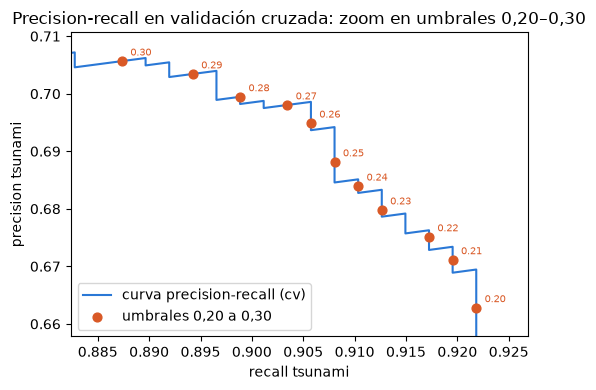

Umbral elegido por validación cruzada: 0.27


In [25]:
# La curva precision-recall de la clase tsunami, con zoom en los umbrales 0,20 a 0,30
#Decisión (ver texto): entre 0,2 y 0,5 el f1 macro empata; dentro del empate se prioriza el recall
UMBRAL = 0.27
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(pr_r, pr_p, color="#2a78d6", label="curva precision-recall (cv)")


ax.scatter(tabla_zoom["recall tsunami"], tabla_zoom["precision tsunami"],
           color="#d95926", s=40, zorder=3, label="umbrales 0,20 a 0,30")
for u in tabla_zoom.index:
    ax.annotate(f"{u:.2f}", (tabla_zoom.loc[u, "recall tsunami"], tabla_zoom.loc[u, "precision tsunami"]),
                textcoords="offset points", xytext=(6, 4), fontsize=7, color="#d95926")

ax.set_xlabel("recall tsunami"); ax.set_ylabel("precision tsunami")
margen = 0.005
ax.set_xlim(tabla_zoom["recall tsunami"].min() - margen, tabla_zoom["recall tsunami"].max() + margen)
ax.set_ylim(tabla_zoom["precision tsunami"].min() - margen, tabla_zoom["precision tsunami"].max() + margen)
ax.set_title("Precision-recall en validación cruzada: zoom en umbrales 0,20–0,30")
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

print(f"Umbral elegido por validación cruzada: {UMBRAL}")


## 9. El test, una sola vez

Todo está decidido: columnas, modelo, hiperparámetros y umbral. Recién ahora se mira el test.

In [26]:
# El test, una sola vez: modelo, hiperparámetros, columnas y umbral ya están decididos
proba_test = elegido.predict_proba(X_test)[:, 1]
pred_test  = (proba_test >= UMBRAL).astype(int)

pd.DataFrame({"validación cruzada (train)": {"f1 macro": f1_score(y_train, (proba_cv >= UMBRAL).astype(int), average="macro"),
                                             "PR-AUC": average_precision_score(y_train, proba_cv)},
              "test": {"f1 macro": f1_score(y_test, pred_test, average="macro"),
                       "PR-AUC": average_precision_score(y_test, proba_test)},
              "piso en test": {"f1 macro": f1_score(y_test, np.zeros_like(y_test), average="macro"),
                               "PR-AUC": y_test.mean()}}).round(3)

,validación cruzada (train),test,piso en test
f1 macro,0.888,0.876,0.489
PR-AUC,0.806,0.804,0.042



0,876 en test contra 0,888 en validación cruzada. La diferencia (0,012, a favor de la validación) es del tamaño del desvío de la validación (0,011): el test confirma lo que dijo la validación, sin señales de que el número estuviera inflado. Contra el piso, el modelo le gana por 39 puntos de f1 macro, y su PR-AUC (que no depende del umbral) es 19 veces la del piso.

In [27]:
print(classification_report(y_test, pred_test, target_names=["sin tsunami (0)", "tsunami (1)"], digits=3))

                 precision    recall  f1-score   support

sin tsunami (0)      0.996     0.979     0.988      2475
    tsunami (1)      0.656     0.917     0.764       108

       accuracy                          0.976      2583
      macro avg      0.826     0.948     0.876      2583
   weighted avg      0.982     0.976     0.978      2583



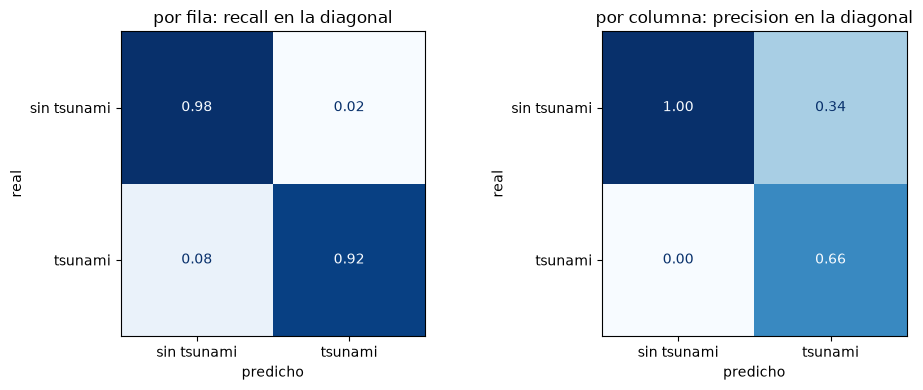

predicho,0,1
real,,
0,2423,52
1,9,99


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (norma, titulo) in zip(axes, [("true", "por fila: recall en la diagonal"),
                                      ("pred", "por columna: precision en la diagonal")]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=ax, cmap="Blues", colorbar=False,
                                            normalize=norma, values_format=".2f",
                                            display_labels=["sin tsunami", "tsunami"])
    ax.set_title(titulo); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout(); plt.show()

pd.crosstab(y_test, pred_test, rownames=["real"], colnames=["predicho"])   # los conteos, para leer junto

Cómo se leen las dos matrices:

- **Por fila (recall):** de los 108 sismos con `tsunami = 1` del test, el modelo marca **99 (92 %)**. Se le escapan 9: es el error caro, y lo comete en uno de cada doce casos.
- **Por columna (precision):** de los 151 sismos que el modelo marca, **99 (66 %)** tienen la marca real. Hay 52 falsas alarmas, el 2,1 % de los 2.475 sismos sin tsunami.

Los dos errores no quedan parejos: 9 falsos negativos contra 52 falsas alarmas. Es el efecto buscado al bajar el umbral. El modelo se inclina a alarmar, porque una alarma de más cuesta menos que un tsunami perdido.

## 10. El modelo, leído

### 10.1 Dónde se equivoca

In [29]:
# Dónde se equivoca, con nombre y apellido: los falsos negativos y los falsos positivos más confiados
casos = datos.loc[X_test.index, ["time", "place", "mag", "magType", "depth", "dist_costa_km", "tsunami"]].assign(
    probabilidad=proba_test.round(3), predicho=pred_test)

falsos_negativos = casos[(casos["tsunami"] == 1) & (casos["predicho"] == 0)].sort_values("probabilidad")
falsos_positivos = casos[(casos["tsunami"] == 0) & (casos["predicho"] == 1)].sort_values("probabilidad", ascending=False)

print(f"Falsos negativos: {len(falsos_negativos)}  ·  Falsos positivos: {len(falsos_positivos)}")
display(falsos_negativos.head(8))
falsos_positivos.head(8)

Falsos negativos: 9  ·  Falsos positivos: 52


,time,place,mag,magType,depth,dist_costa_km,tsunami,probabilidad,predicho
10136,2020-10-08 07:35:32.524+00:00,"40 km ENE of Kainantu, Papua New Guinea",6.3,mww,106.000,-58.87,1,0.056,0
7481,2022-01-21 16:08:37.210+00:00,"27 km SSE of Saiki, Japan",6.3,mww,39.000,14.11,1,0.071,0
2099,2025-04-13 20:03:22.841+00:00,south of the Fiji Islands,6.5,mww,271.000,591.82,1,0.088,0
10720,2020-05-18 06:56:01.579+00:00,"251 km W of Ferndale, California",5.0,mww,10.000,242.96,1,0.122,0
1872,2025-06-06 17:15:06.807+00:00,"45 km SW of Diego de Almagro, Chile",6.4,mww,75.000,-30.63,1,0.126,0
10719,2020-05-18 07:02:34.591+00:00,"249 km W of Ferndale, California",5.3,mww,10.000,241.13,1,0.144,0
8442,2021-08-09 09:41:58.491+00:00,"211 km WNW of Attu Station, Alaska",5.1,mb,10.000,163.29,1,0.176,0
3156,2024-08-10 03:28:32.681+00:00,"151 km E of Dolinsk, Russia",6.5,mww,402.166,112.04,1,0.198,0


,time,place,mag,magType,depth,dist_costa_km,tsunami,probabilidad,predicho
8816,2021-05-19 00:42:19.688+00:00,southern East Pacific Rise,6.7,mww,10.00,655.33,0,0.908,1
4627,2023-10-07 08:40:11.361+00:00,"48 km SE of Madang, Papua New Guinea",6.9,mww,52.00,10.36,0,0.891,1
5830,2023-01-09 17:47:35.037+00:00,"Pulau Pulau Tanimbar, Indonesia",7.6,mww,104.95,87.35,0,0.875,1
8027,2021-09-24 07:02:29.055+00:00,"185 km WSW of Adak, Alaska",5.5,mww,18.00,89.76,0,0.868,1
3165,2024-08-08 07:42:55.206+00:00,"2024 Hyuganada Sea, Japan Earthquake",7.1,mww,24.00,3.27,0,0.845,1
10880,2020-03-31 23:52:30.781+00:00,"Stanley, Idaho",6.5,mww,12.06,-646.02,0,0.807,1
7529,2022-01-11 12:53:45.679+00:00,"82 km SE of Nikolski, Alaska",5.8,mww,16.72,76.65,0,0.803,1
6755,2022-06-15 11:56:33.191+00:00,off the coast of Oregon,5.6,mww,10.00,477.86,0,0.799,1


In [30]:
# Los errores, resumidos: magnitud mediana y región más frecuente
region_test = datos.loc[X_test.index, "place"].str.split(", ").str[-1]
pd.DataFrame({
    "aciertos tsunami":   {"cantidad": int(((casos.tsunami == 1) & (casos.predicho == 1)).sum()),
                           "mag mediana": casos[(casos.tsunami == 1) & (casos.predicho == 1)]["mag"].median()},
    "falsos negativos":   {"cantidad": len(falsos_negativos), "mag mediana": falsos_negativos["mag"].median()},
    "falsos positivos":   {"cantidad": len(falsos_positivos), "mag mediana": falsos_positivos["mag"].median()}}).T.assign(
    **{"región más frecuente": [region_test[casos[(casos.tsunami == 1) & (casos.predicho == 1)].index].mode()[0],
                                region_test[falsos_negativos.index].mode()[0] if len(falsos_negativos) else "",
                                region_test[falsos_positivos.index].mode()[0] if len(falsos_positivos) else ""]})

,cantidad,mag mediana,región más frecuente
aciertos tsunami,99.0,6.0,Alaska
falsos negativos,9.0,6.3,California
falsos positivos,52.0,5.6,Alaska


**Los 9 falsos negativos** tienen magnitud mediana 6,3. Todos tienen probabilidad menor a 0,25, así que el modelo los descarta con bastante confianza. Son de tres tipos:

1. **Sismos de 6,3 a 6,5 fuera de Alaska y la costa oeste**, varios en tierra o profundos: Papúa Nueva Guinea (en tierra, 106 km de profundidad, 0,06), Saiki en Japón (0,07), sur de Fiji (271 km, 0,09), Chile (en tierra, 0,13) y Rusia (402 km, 0,20).
2. **Sismos chicos (5,0 a 5,3) en el mar frente a California y Alaska** (Ferndale, Attu), con 0,12 a 0,18, que la USGS marcó con su umbral regional y el modelo no.
3. **Un sismo de 6,1 en el Caribe** (Islas Caimán, 0,24), una región casi sin marcas en los datos.

**Qué cambió al bajar el umbral de 0,5 a 0,27:** se recuperaron 14 tsunamis que el modelo veía con probabilidad entre 0,27 y 0,5. La mitad son sismos de 5,0 a 5,4 en Alaska; el resto, sismos de 6,2 a 6,5 en Vanuatu, Papúa Nueva Guinea, Indonesia, Rusia y las Sandwich del Sur. A cambio aparecieron 20 falsas alarmas nuevas, del mismo tipo: 11 sismos de 5,0 a 5,2 en Alaska, y sismos de 6,1 a 7,0 en el Pacífico (Fiji, Tonga, México, Panamá, Indonesia). Tres de ellas son muy profundas (Guatemala a 252 km, Rusia a 344 km, Java a 597 km). El umbral bajo no inventa un error nuevo: amplía la franja dudosa en la que la USGS a veces marca y a veces no.

**Las falsas alarmas más confiadas** también son de dos tipos, y los dos se explican desde el dominio:

1. **Sismos fuertes (6,7 a 7,6) en el mar o pegados a la costa**: la dorsal del Pacífico Este (M 6,7), Madang en Papúa Nueva Guinea (M 6,9), Tanimbar en Indonesia (M 7,6) y Hyuganada en Japón (2024, M 7,1, 24 km de profundidad, a 3 km de la costa), con probabilidades de 0,85 a 0,91. Por magnitud y ubicación son el caso típico que la USGS marca; esta vez no lo hizo.
2. **Sismos moderados (5,5 a 5,8) en Alaska y frente a Oregon** con `tsunami = 0`, con probabilidades de 0,80 a 0,87. Ahí la USGS a veces marca y a veces no, con un criterio que no está en nuestras columnas. En la misma línea, un sismo en tierra (Stanley, Idaho, M 6,5, a 646 km de la costa) recibe 0,81: la caja geográfica de Norteamérica pesa aunque el sismo esté lejos del mar.

Además, el modelo **casi no usa la profundidad** (sección 6), y la etiqueta tampoco: en los datos hay **19 sismos a más de 300 km de profundidad con `tsunami = 1`** (Fiji, Vanuatu, Japón), aunque físicamente un sismo tan profundo casi no deforma el fondo del mar. La USGS marca por magnitud y región aunque el sismo sea profundo. Es la mejor evidencia de que predecimos la marca, no la física del tsunami.

### 10.2 En qué se apoya

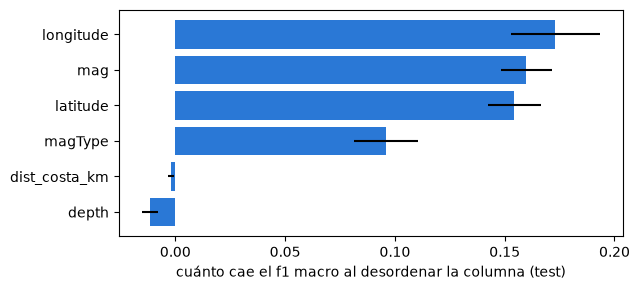

,caída de f1 macro,desvío
longitude,0.173,0.020
mag,0.160,0.012
latitude,0.154,0.012
magType,0.096,0.015
dist_costa_km,-0.002,0.001
depth,-0.012,0.004


In [31]:
# En qué se apoya: importancia por permutación sobre el test, con la métrica declarada.
# Se permuta cada columna cruda (magType entera, no cada columna del one-hot).
COLUMNAS_MODELO = NUMERICAS + CATEGORICAS + ["dist_costa_km"]      # dist_costa_km → es_oceanico
imp = permutation_importance(elegido, X_test[COLUMNAS_MODELO], y_test, scoring="f1_macro",
                             n_repeats=10, random_state=SEMILLA, n_jobs=-1)

importancias = (pd.DataFrame({"caída de f1 macro": imp.importances_mean, "desvío": imp.importances_std},
                             index=COLUMNAS_MODELO).sort_values("caída de f1 macro"))
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(importancias.index, importancias["caída de f1 macro"], xerr=importancias["desvío"], color="#2a78d6")
ax.set_xlabel("cuánto cae el f1 macro al desordenar la columna (test)")
plt.tight_layout(); plt.show()
importancias.sort_values("caída de f1 macro", ascending=False).round(3)

Al desordenar cada columna en el test:

- **`mag` pesa mucho** (el f1 cae 0,16). Es lo esperado y lo que mostró el semáforo de la Entrega 2.
- **`latitude` y `longitude` pesan lo mismo que la magnitud**: la longitud un poco más (0,17) y la latitud un poco menos (0,15). Es la columna que sorprende, y por eso **la revisamos como posible fuga**:
  - ¿Existe al predecir? Sí: las coordenadas son lo primero que se conoce de un sismo.
  - ¿Contiene la respuesta? No: no se calcula a partir de la etiqueta.
  - ¿Por qué pesa tanto? Por la regla regional de la sección 2.1: la USGS marca sismos moderados cerca de Alaska y la costa oeste que en el resto del mundo no marcaría. El mapa de abajo lo muestra.
  - Conclusión: **no es fuga, es la política de la etiqueta.** El modelo aprendió dónde la USGS es más estricta.
- **`magType` pesa algo** (0,10).
- **`depth` y `es_oceanico` no pesan nada** (−0,012 y −0,002: desordenarlas no baja el f1), coherente con la ablación de la sección 6.

Nota: la importancia por permutación mide sobre el `predict` del modelo (umbral 0,5).

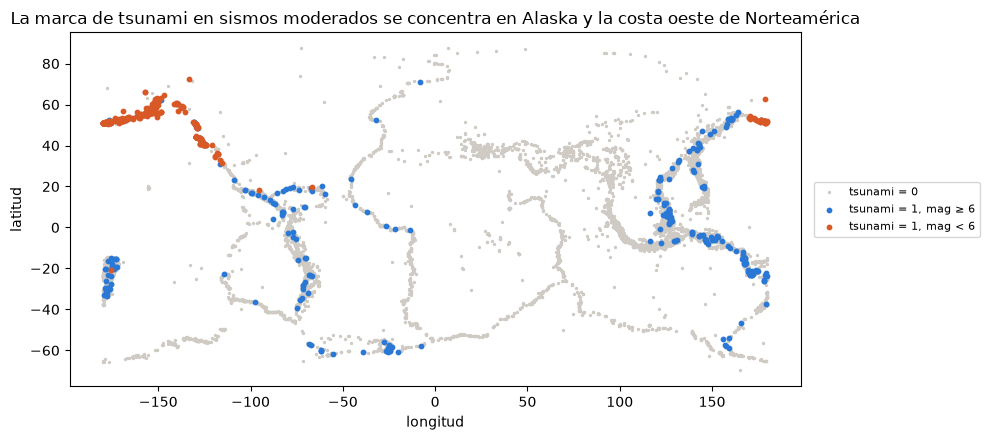

In [32]:
# La columna que más pesa, mirada en un mapa: dónde están los tsunami = 1 con magnitud menor a 6
fig, ax = plt.subplots(figsize=(10, 4.5))
base = datos[datos["tsunami"] == 0]
ax.scatter(base["longitude"], base["latitude"], s=2, color="#cfcac3", label="tsunami = 0")
for (cond, color, etiqueta) in [((datos["tsunami"] == 1) & (datos["mag"] >= 6), "#2a78d6", "tsunami = 1, mag ≥ 6"),
                                ((datos["tsunami"] == 1) & (datos["mag"] < 6),  "#d95926", "tsunami = 1, mag < 6")]:
    s = datos[cond]
    ax.scatter(s["longitude"], s["latitude"], s=10, color=color, label=etiqueta)
ax.set_xlabel("longitud"); ax.set_ylabel("latitud"); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
ax.set_title("La marca de tsunami en sismos moderados se concentra en Alaska y la costa oeste de Norteamérica")
plt.tight_layout(); plt.show()

Los puntos naranjas (marca de tsunami con magnitud menor a 6) están casi todos en Alaska y la costa oeste de Norteamérica. Los azules (magnitud 6 o más) están en todo el Cinturón de Fuego del Pacífico. **Eso es lo que aprende el modelo con la latitud y la longitud.**

### 10.3 Las reglas, en un árbol chico

El boosting combina hasta 100 árboles y no se puede leer directamente. Un árbol de tres preguntas con las mismas columnas sirve como lupa para ver qué cortes usa.

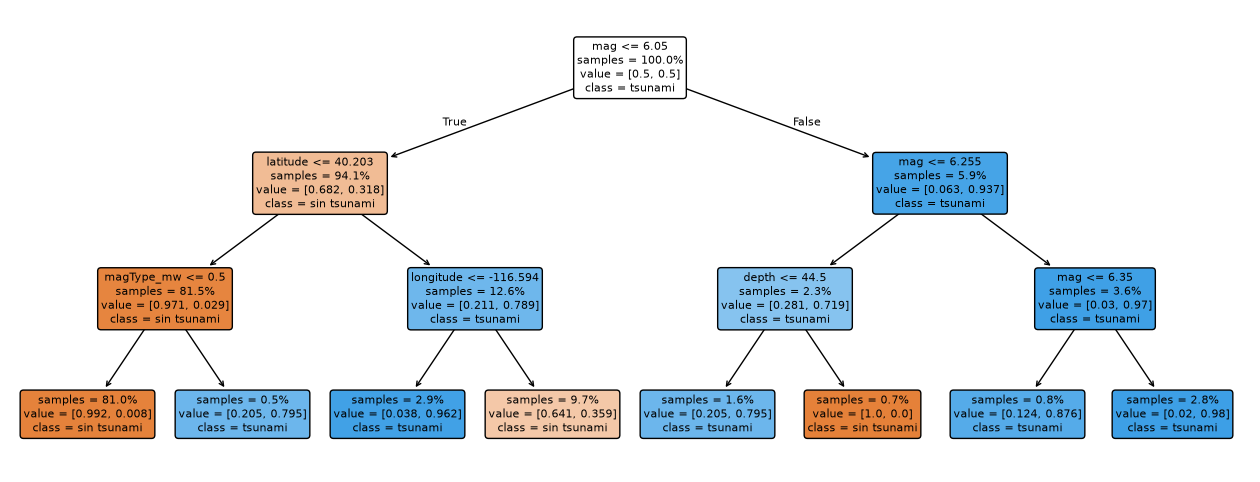

f1 macro del árbol chico en validación cruzada: 0.799


In [33]:
# Un árbol chico (3 preguntas) con las mismas columnas, para leer las reglas que el boosting aprende combinadas.
# No es el modelo final: es una lupa. Sin escalar, para que los cortes se lean en unidades reales.
arbol_chico = armar(DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMILLA),
                    escalar=False).fit(X_train, y_train)
nombres = [n.split("__")[-1] for n in arbol_chico[:-1].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(arbol_chico[-1], feature_names=nombres, class_names=["sin tsunami", "tsunami"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=8, ax=ax)
plt.show()
print("f1 macro del árbol chico en validación cruzada:", round(medir(clone(arbol_chico))["f1 medio"], 3))

El árbol se lee como la regla de la USGS:

- **Primera pregunta: ¿magnitud mayor a 6,05?** Si es así, casi siempre hay marca (rama derecha, 94 % de los casos ponderados).
- **Si la magnitud es menor**, la pregunta siguiente es **dónde**: latitud mayor a 40,2° y longitud menor a −116,6° es una caja que contiene Alaska y el noroeste de Norteamérica. Dentro de esa caja, el 96 % de los casos ponderados tiene marca aunque el sismo sea moderado. Al sur de 40,2° el árbol sólo usa el tipo de magnitud (`magType = mw`), que separa un grupo chico (0,5 % de los sismos).
- **Entre 6,05 y 6,255 aparece la profundidad**: hasta 44,5 km hay marca; por encima, no. Es el único lugar donde la profundidad decide algo, y afecta al 2,3 % de los sismos. Eso explica por qué en la ablación sacarla casi no cambia nada.

(Los valores de cada nodo están ponderados por `class_weight="balanced"`, por eso la raíz dice 0,5 / 0,5.)

Con tres preguntas el árbol chico llega a 0,799 de f1 macro. El boosting suma 8 puntos combinando muchos cortes de este tipo.

## 11. Conclusiones

**Respuesta a la pregunta del proyecto:** las características que permiten estimar si un sismo está asociado a una marca de tsunami son **la magnitud y la ubicación** (latitud y longitud), con un peso parecido. El tipo de magnitud aporta un poco. La profundidad, la distancia a la costa y las métricas de calidad de la red (`nst`, `dmin`, `gap`, `rms`) no agregan nada una vez que el modelo tiene magnitud y ubicación.

**Lo que el modelo dice que los datos solos no decían:** en la Entrega 2 la magnitud ya separaba bien, pero el 21,7 % de los sismos mayores a 7,5 no tenía la marca y no sabíamos por qué. El modelo muestra que la otra mitad de la regla es **dónde** ocurre el sismo, y que la marca refleja criterios regionales de alerta de la USGS además de la física del sismo.

| | f1 macro | Desvío |
|---|---|---|
| Piso (siempre «no tsunami») | 0,489 | 0,000 |
| Regresión logística | 0,747 | 0,025 |
| Gradient boosting, por defecto | 0,867 | 0,016 |
| Gradient boosting ajustado, umbral 0,27, validación cruzada | 0,888 | — |
| **Gradient boosting ajustado, umbral 0,27, test (una vez)** | **0,876** | — |

Con el umbral 0,27, en test el modelo detecta **92 % de los sismos marcados** (99 de 108) y 66 de cada 100 alertas son correctas.

**Lo que probamos y no anduvo:**

- `nst`, `dmin`, `gap` y `rms`: empatan solas y juntas; ninguna mejora el modelo.
- La distancia a la costa continua: empata con la binaria, y las dos empatan con no tenerla.
- `depth`: no aporta; el modelo no distingue un sismo profundo de uno superficial, igual que la etiqueta de la USGS.
- Ajustar hiperparámetros: mejoró 1,4 puntos, en el límite del ruido.
- Balancear con `class_weight`: el mejor modelo balanceado empata con el mejor sin balancear y es menos estable.
- Mover el umbral no cambia el f1 (plano entre 0,2 y 0,5), pero sí el reparto entre recall y precision. Lo usamos para priorizar el recall: umbral 0,27.
- Partir por grupo o por fecha en vez de al azar: dio lo mismo, porque las réplicas no llevan la marca.

**Pendientes para la Entrega 4:**

- Re-congelar el dataset cuando la USGS haya cargado la marca de abril–julio 2026.
- Aclarar en la aplicación que el modelo predice la **marca de la USGS**, no la ocurrencia de un tsunami.

## 12. El modelo para la Entrega 4

In [34]:
# El modelo para la Entrega 4: el pipeline entrenado más el umbral elegido
import joblib
joblib.dump({"pipeline": elegido, "umbral": UMBRAL, "columnas": CANDIDATAS, "semilla": SEMILLA,
             "datos_hasta": CORTE}, "modelo_tsunami_e3.joblib")

# así se usa: un sismo nuevo, una probabilidad, una decisión
nuevo = pd.DataFrame([{"mag": 7.2, "depth": 25, "latitude": -33.5, "longitude": -72.0, "magType": "mww",
                       "dist_costa_km": 40, "nst": np.nan, "dmin": np.nan, "gap": np.nan, "rms": np.nan}])
p = elegido.predict_proba(nuevo)[0, 1]
pd.Series({"probabilidad de tsunami = 1": round(p, 3), "alerta": "sí" if p >= UMBRAL else "no"})

probabilidad de tsunami = 1    0.808
alerta                            sí
dtype: object